## 🟡 LEVEL 2: MEDIUM - HR Employee Records Dataset

### Business Context
Human Resources database containing employee master data with performance metrics and compensation information.

### Column Descriptions
1. **EmployeeID** - Unique employee identifier (EMP00001-EMP01900)
2. **FirstName** - Employee first name
3. **LastName** - Employee surname
4. **Department** - Department assignment (Sales, IT, HR, Finance, Operations, Marketing, R&D)
5. **Position** - Job title (Manager, Senior, Junior, Intern, Analyst, Engineer, Coordinator)
6. **JoinDate** - Hire date (mixed formats)
7. **BaseSalary** - Annual salary (with outliers)
8. **Bonus** - Annual bonus (mixed NULL representations)
9. **AgeYears** - Employee age (with negative values)
10. **Gender** - Gender identity (M, F, Other, NA)
11. **PerformanceRating** - Annual rating (mixed cases and formats)
12. **YearsExperience** - Total years in field
13. **ManagerID** - Direct manager's EmployeeID
14. **Email** - Work email (with duplicates)
15. **EmploymentStatus** - Active/Inactive/On Leave

### 🔍 Data Quality Issues (MEDIUM)

#### Issue #1: Multiple NULL Representations (8% of data)
- **Location**: Bonus column
- **Type**: np.nan, 'NA', 'N/A', -999
- **Real-world scenario**: Data from multiple systems/sources with different encoding
- **Challenge**: Standardize all NULL representations
- **Skills**: Pattern recognition, data standardization, replacement strategies

```
Before: [5000.0, np.nan, 'NA', 'N/A', -999, 2500.0]
After:  [5000.0, np.nan, np.nan, np.nan, np.nan, 2500.0]
```

#### Issue #2: Inconsistent Categorical Values (5% of data)
- **Location**: Department column
- **Type**: Typos, extra whitespace, abbreviations
- **Real-world scenario**: Manual entry variations, abbreviation inconsistency
- **Challenge**: Map variants to correct values
- **Skills**: Fuzzy matching, category standardization, value mapping

```
Before: ['Sales', 'sales ', 'I.T', 'hr  ', 'Finance']
After:  ['Sales', 'Sales', 'IT', 'HR', 'Finance']
```

#### Issue #3: Impossible Values (2% of data)
- **Location**: AgeYears column
- **Type**: Negative ages (-45 years old)
- **Real-world scenario**: Data entry errors, sign reversal bugs
- **Challenge**: Identify and correct logically impossible values
- **Skills**: Business rule validation, outlier detection

```
Before: [28, -45, 32, -22, 51]
After:  [28, 45, 32, 22, 51] OR [28, NaN, 32, NaN, 51]
```

#### Issue #4: Extreme Outliers (3% of data)
- **Location**: BaseSalary column
- **Type**: Values like 999999, 1 (far outside reasonable range)
- **Real-world scenario**: Data entry typos, placeholder values, system errors
- **Challenge**: Identify legitimate extremes vs. errors
- **Skills**: Outlier detection, distribution analysis, domain knowledge application

```
Before: [45000, 120000, 999999, 85000, 1, 95000]
After:  [45000, 120000, NaN, 85000, NaN, 95000] 
        (or investigation to determine if legitimate)
```

#### Issue #5: Inconsistent Categorical Formatting (4% of data)
- **Location**: PerformanceRating column
- **Type**: Mixed cases ('EXCELLENT', 'good', 'Excellent', 'Good')
- **Real-world scenario**: Different versions of rating system, legacy data
- **Challenge**: Standardize all variations to canonical format
- **Skills**: Case normalization, value mapping

```
Before: ['Excellent', 'EXCELLENT', 'good', 'Good', 'AVERAGE']
After:  ['Excellent', 'Excellent', 'Good', 'Good', 'Average']
```

#### Issue #6: Duplicate Emails (2% of data)
- **Location**: Email column
- **Type**: Multiple employees with same email
- **Real-world scenario**: Test data mixed in, employee transfers, email system errors
- **Challenge**: Identify and investigate duplicates
- **Skills**: Finding duplicates by column, cross-reference checks

```
Before: [emp1@company.com, emp2@company.com, emp1@company.com, emp3@company.com]
After: Investigate which records are legitimate duplicates
```

#### Issue #7: Mixed Date Formats (4% of data)
- **Location**: JoinDate column
- **Type**: Multiple date representations (DD/MM/YYYY, YYYYMMDD)
- **Real-world scenario**: Data merged from multiple systems
- **Challenge**: Parse and standardize dates from different formats
- **Skills**: Advanced date parsing, format detection

```
Before: ['15/01/2020', '20200115', datetime(2020,1,15), '2020-01-15']
After:  ['2020-01-15', '2020-01-15', '2020-01-15', '2020-01-15']
```

### 🎯 Key Cleaning Tasks
1. Standardize all NULL representations
2. Fix inconsistent department/position names
3. Correct impossible age values
4. Identify and handle salary outliers
5. Standardize all categorical values (case, encoding)
6. Find and flag duplicate emails
7. Parse and convert mixed date formats
8. Validate data ranges and business rules

### 💡 Estimated Time: 3-5 hours

### **Let's Go Then........**

**STEP 1: Data Ingestion**

Let's perfectly read the dataset, import it from the file path.

In [3]:
import pandas as pd
import numpy as np
import os


# File path.
file_path: str = 'messy_datasets_(3 sheets).xlsx'

# let's validate the file than open.
if os.path.exists(file_path):
    try:
        # we'll open the sheet 2, cause we know where it lies down.
        df_employee = pd.read_excel(file_path, sheet_name='Medium_Level')
        print(f'File Loaded succesfull! DataFrame contains {len(df_employee)} rows.')
    except Exception as e:
        print(f'could not open the File! {e}')
else:
    raise FileNotFoundError('File Not Exists!')
    

File Loaded succesfull! DataFrame contains 1900 rows.


**STEP 2: Data Profilling and Inspection**

let's see  the preassigned datatypes by pandas, Statistical Overview of some numericals value.

In [4]:
df_employee.info()

<class 'pandas.DataFrame'>
RangeIndex: 1900 entries, 0 to 1899
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   EmployeeID         1900 non-null   str    
 1   FirstName          1900 non-null   str    
 2   LastName           1900 non-null   str    
 3   Department         1900 non-null   str    
 4   Position           1900 non-null   str    
 5   JoinDate           1900 non-null   object 
 6   BaseSalary         1900 non-null   float64
 7   Bonus              1786 non-null   float64
 8   AgeYears           1900 non-null   int64  
 9   Gender             1424 non-null   str    
 10  PerformanceRating  1900 non-null   str    
 11  YearsExperience    1900 non-null   int64  
 12  ManagerID          1900 non-null   str    
 13  Email              1900 non-null   str    
 14  EmploymentStatus   1900 non-null   str    
dtypes: float64(2), int64(2), object(1), str(10)
memory usage: 361.7+ KB


**NOTE: Expected columns to be Changed in respect to their Datatypes**

- _JoinDate_ : before `object` expected `datetime64`.
- _Department_: before `str` expected `Category`.
- _Positions_: before `str` expected `Category`.
- _Gender_: before `str` expected `Category`.
- _PerformanceRating_: before `str` expected `Category`.
- _EmploymentStatus_: before `str` expected `Category`.

Why Choose Category datatype?

All the columns I've selcted to assign Category datatypes have low cardinality, Which means out of our 1900 columns There are probably only 5 distinct `Departments`, 3 or 4 `Gender` types, as same in `Positions` , `PerformanceRating` , and `EmploymentStatus`.

Right now, Pandas are storing the string `Finance` in memory hundreds of times, which fills are memory, if the data scales for 5 million rows our RAM will max out instantly.

And that's why we use **Category** Datatype to efficiently use our memory, behind the hood, pandas sotre each strings e.g. `Finance` strings only at onece in our memory and assign it an integer code e.g. (like `0`) and just use the integer under the hood, that reduce memory usage for atmost 90% and make the `.groupby` operations lightning fast.


In [5]:
# The Statistical overview of our numerical columns.
df_employee.describe()

,BaseSalary,Bonus,AgeYears,YearsExperience
count,1900.000000,1786.000000,1900.000000,1900.000000
mean,103194.122263,15155.726390,41.366316,19.541579
std,115451.384030,9057.635833,17.498379,11.480682
min,1.000000,-999.000000,-64.000000,0.000000
25%,61262.108273,7287.753619,32.000000,10.000000
50%,90911.899293,15675.294440,42.000000,19.500000
75%,122006.715112,22925.546654,54.000000,29.000000
max,999999.000000,29997.029310,64.000000,39.000000


**By seeing just the Overview, We found multiple Anomalies**

- _BaseSalary_: look at the mean, std , min and max, we have 1 for the minimum and 999999 for maximum, The anamoly, how can an employee have the salary such like that.

Same goes for _Bonus_ and _AgeYears_ columns, the age year column has minimum -64 years , which is absolutely Not Possible via any logic.

**NOTE**: We'll fix all of them on further Operations. currently we should stick with the Standard Industry Data Cleaning Order.

**STEP 3: Structural Standardization**

Striping empty white spaces around the columns name, applying them to an standard Format, and Droping compeletly empty rows which are for the human readablity concerns.

In [6]:
# Striping all the white spaces.
df_employee.columns = df_employee.columns.str.strip()

# Since the columns are perfectly Formated there's no need to alter any thing.

# However always make sure to drop the completely empty columns.
df_employee = df_employee.dropna(axis=1, how='all')

# axis 1 says move to the columns side and how says, if all the rows of the is 
# NaN or null values only, then drop.

df_employee.columns # Done.

Index(['EmployeeID', 'FirstName', 'LastName', 'Department', 'Position',
       'JoinDate', 'BaseSalary', 'Bonus', 'AgeYears', 'Gender',
       'PerformanceRating', 'YearsExperience', 'ManagerID', 'Email',
       'EmploymentStatus'],
      dtype='str')

**STEP 4: Deduplication**

First go for Exact Duplicates, than for Partial Duplicates which would be handled via various Business logic.

In [7]:
"""Exact Duplicates."""

# let's count the total number of exact dups.
total_exact_dups: int = df_employee.duplicated().sum()
print(f'Data set contains {total_exact_dups} Exact Dups.')

# well nothing to handle here.

Data set contains 0 Exact Dups.


In [8]:
"""Partial Duplicates"""

# let's see how many dupes does each columns have , and then we'll handle them
# accodingly.

spaces: int = 20
for col in df_employee.columns:
    print(f"{col}{" "*(spaces - len(col))}{df_employee[col].duplicated().sum()}")

EmployeeID          0
FirstName           1892
LastName            1892
Department          1890
Position            1893
JoinDate            371
BaseSalary          55
Bonus               150
AgeYears            1833
Gender              1896
PerformanceRating   1894
YearsExperience     1860
ManagerID           1602
Email               35
EmploymentStatus    1897


**NOTE: Partial Deduplication**

The good news is the _primary key_ `EmployeeID` doesn't contains any duplicates, all of them are unique.

However, if every employee is unique , why should they have same emails?
we have 35 duplicates on email section, which shouldn't be there.

let's see....

In [9]:
"""
Well for now I'm gonna flag the duplicate emails as pandas NA Type, 
we'll handle it at the part of Handling missing values.

"""
# Created a boolean mask whereever the email contains duplicated values and
# Excluding the first Occurance.
bool_mask: bool = df_employee['Email'].duplicated()

# Making them a missing value.
df_employee.loc[bool_mask, 'Email'] = pd.NA

# Now we handled the duplicate part, but now it becomes null values, 
# which would be handled in later part.
df_employee['Email'].isna().sum()

np.int64(35)

The Duplication part is over, let's go for the next step.

**STEP 5: Data Type Casting**

Expected columns to be Changed in respect to their Datatypes

- _JoinDate_ : before `object` expected `datetime64`.
- _Department_: before `str` expected `Category`.
- _Position_: before `str` expected `Category`.
- _Gender_: before `str` expected `Category`.
- _PerformanceRating_: before `str` expected `Category`.
- _EmploymentStatus_: before `str` expected `Category`.

In [10]:
"""
The JoinDate column:

The JoinDate column has object dtype-
- let's remove the 00:00:00 extension first to each columns
- Check how many formate of dates are present in there
- hadle them accordingly and convert them into standard date time formate.
"""
# Let's remove the 00:00:00 extension first, we'll use the regex method.
df_employee['JoinDate'] = df_employee['JoinDate'].astype('str') # first we have to convert the column in string dtype, for performing regex operations.
df_employee['JoinDate'] = df_employee['JoinDate'].str.replace(r'\d{2}:\d{2}:\d{2}', "", regex=True).str.strip()

# we've removed the 00:00:00 extension, Now let's see how many formats JoinDate contains.

# A very professional method is that, convert every digits into X in date column.
# 2022-02-28 will become XXXX-XX-XX and so are the 10/05/2024 becomes XX/XX/XXXX.
# and then we'll group by and see how many format does we have.

# Created a new column called DateFormat.
df_employee['DateFormat'] = df_employee['JoinDate'].str.replace(r'\d', 'X', regex=True)

# df_employee[df_employee['DateFormat']=='XX/XX/XXXX'].head()
# DateFormat
# XXXX-XX-XX    1824
# XXXXXXXX        38
# XX/XX/XXXX      38
# Name: count, dtype: int64

In [11]:
# Let's hadle them now.

# We'll handle them via the Industry standard method.

# Step 1: create an empty series of NaT with the length of our original Dataset.
cleaned_date = pd.Series(pd.NaT, index= df_employee.index) 

# Step 2: create a list of formate we have.
fmt_to_try: list = [
    '%Y-%m-%d', # 2024-02-24
    '%Y%m%d', # 20030925
    '%d/%m/%Y' # 24/04/2003
]

# Step 3: For each formate we'll convert them into date time and assigned it a new Series
# Called parsed_attempt.
for fmt in fmt_to_try:
    parsed_attempt = pd.to_datetime(df_employee['JoinDate'], format=fmt, errors='coerce')

    cleaned_date = cleaned_date.fillna(parsed_attempt)

# Step 4: replace our JoinDate column with cleaned__date.
df_employee['JoinDate'] = cleaned_date

# Well we fixed them. let's verify.

df_employee['DateFormat'].value_counts()

DateFormat
XXXX-XX-XX    1824
XXXXXXXX        38
XX/XX/XXXX      38
Name: count, dtype: int64

**Let's move on to the remaining columns**

- Department
- Position
- Gender
- PerformanceRating
- EmploymentStatus

since all of them should be in category, let's check does each column contains any spelling outliers. like['Good', 'good', 'GOOD']

In [12]:
columns_list: list = [
    'Department',
    'Position',
    'Gender',
    'PerformanceRating',
    'EmploymentStatus'
    ]

for col in columns_list:
    print(df_employee[col].unique())

<ArrowStringArray>
[ 'Marketing',    'Finance',         'HR',      'Sales', 'Operations',
        'I.T',         'IT',        'R&D',     'sales ',       'hr  ']
Length: 10, dtype: str
<ArrowStringArray>
['Coordinator', 'Analyst', 'Intern', 'Engineer', 'Manager', 'Senior',
 'Junior']
Length: 7, dtype: str
<ArrowStringArray>
['F', 'Other', nan, 'M']
Length: 4, dtype: str
<ArrowStringArray>
['Good', 'Average', 'Excellent', 'Below Average', 'good', 'EXCELLENT']
Length: 6, dtype: str
<ArrowStringArray>
['Inactive', 'On Leave', 'Active']
Length: 3, dtype: str


we gotta fix some of them columns, before Casting them into category dtype.

In [13]:
department_mapping = {
    'hr':'HR',
    'I.T': 'IT',
    'sales': 'Sales'
}

performance_mapping = {
    'good': 'Good',
    'EXCELLENT': 'Excellent'
}

df_employee['Department'] = df_employee['Department'].str.strip().str.replace(department_mapping)
df_employee['PerformanceRating'] = df_employee['PerformanceRating'].str.strip().str.replace(performance_mapping)

# let's verify them.
columns_list: list = [
    'Department',
    'Position',
    'Gender',
    'PerformanceRating',
    'EmploymentStatus'
    ]

for col in columns_list:
    print(df_employee[col].unique())

<ArrowStringArray>
['Marketing', 'Finance', 'HR', 'Sales', 'Operations', 'IT', 'R&D']
Length: 7, dtype: str
<ArrowStringArray>
['Coordinator', 'Analyst', 'Intern', 'Engineer', 'Manager', 'Senior',
 'Junior']
Length: 7, dtype: str
<ArrowStringArray>
['F', 'Other', nan, 'M']
Length: 4, dtype: str
<ArrowStringArray>
['Good', 'Average', 'Excellent', 'Below Average']
Length: 4, dtype: str
<ArrowStringArray>
['Inactive', 'On Leave', 'Active']
Length: 3, dtype: str


In [14]:
# Now convert each column to Category.
columns_list: list = [
    'Department',
    'Position',
    'Gender',
    'PerformanceRating',
    'EmploymentStatus'
    ]
for col in columns_list:
    df_employee[col] = df_employee[col].astype('category')

df_employee.info()

<class 'pandas.DataFrame'>
RangeIndex: 1900 entries, 0 to 1899
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   EmployeeID         1900 non-null   str           
 1   FirstName          1900 non-null   str           
 2   LastName           1900 non-null   str           
 3   Department         1900 non-null   category      
 4   Position           1900 non-null   category      
 5   JoinDate           1900 non-null   datetime64[ns]
 6   BaseSalary         1900 non-null   float64       
 7   Bonus              1786 non-null   float64       
 8   AgeYears           1900 non-null   int64         
 9   Gender             1424 non-null   category      
 10  PerformanceRating  1900 non-null   category      
 11  YearsExperience    1900 non-null   int64         
 12  ManagerID          1900 non-null   str           
 13  Email              1865 non-null   str           
 14  EmploymentStatus   

Completed the data types casting, let's go for...

**STEP 6. Handling Missing Values**

In [15]:
# let's check which column has how much missing values.
spaces: int = 20
for col in df_employee.columns:
    print(f'{col}{" "*(spaces-len(col))}{df_employee[col].isna().sum()}')

EmployeeID          0
FirstName           0
LastName            0
Department          0
Position            0
JoinDate            0
BaseSalary          0
Bonus               114
AgeYears            0
Gender              476
PerformanceRating   0
YearsExperience     0
ManagerID           0
Email               35
EmploymentStatus    0
DateFormat          0


So these are the following columns which contains missing values.

- Bonus
- Gender
- Email

<Axes: >

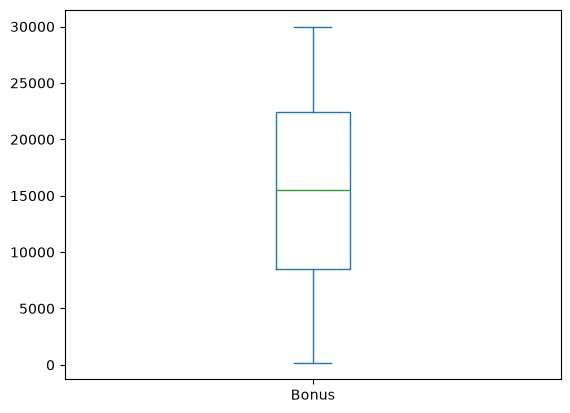

In [20]:
# Let's see what could be done for Bonus, since it also conatains anamolies
# Such as negetive values.

# let's round the column values first.
df_employee['Bonus'] = df_employee['Bonus'].round(2)
df_employee.head()

# the -999.00 or -99.00 are the specific values In data engineering 
# is frequently used as a hardcoded placeholder to represent "missing"
# or "error" data, rather than being an actual financial amount.

# let's replace the hardcoded value -999.00, -99.00
df_employee['Bonus'] = df_employee['Bonus'].replace(-999.00, np.nan)

# df_employee['Bonus'].isna().sum()
# df_employee.head(49)

# We use the graph to find out the outliers.
df_employee['Bonus'].plot(kind='box')

In [21]:
# since we cannot see the massive amount of bonus as anomaly in 
# business logic , since it might be of a CEOs bonuses, whereas
# we have to set a lower threshold for bonuses let's make $200, any 
# bonuses below $200 will replaced to $200.

bool_mask_bonus = (df_employee['Bonus'] < 200)
df_employee.loc[bool_mask_bonus, 'Bonus'] = 200.00

# Since we handled the anomaies, let's fill the missing value with averages.
df_employee['Bonus'] = df_employee['Bonus'].fillna(df_employee['Bonus'].mean())
df_employee = df_employee.drop(columns='DateFormat')
df_employee.head()

,EmployeeID,FirstName,LastName,Department,Position,JoinDate,BaseSalary,Bonus,AgeYears,Gender,PerformanceRating,YearsExperience,ManagerID,Email,EmploymentStatus
0,EMP00001,John,Johnson,Marketing,Coordinator,2022-01-28,41666.930151,15507.62,22,F,Good,6,EMP00100,emp0@company.com,Inactive
1,EMP00002,Lisa,Miller,Finance,Analyst,2024-04-17,1.000000,24982.71,40,F,Average,21,EMP00089,emp1@company.com,On Leave
2,EMP00003,Sarah,Jones,HR,Analyst,2017-06-02,31812.893471,20149.97,38,Other,Excellent,19,EMP00123,emp2@company.com,On Leave
3,EMP00004,David,Johnson,Marketing,Intern,2020-07-20,137792.767813,5278.25,49,Not Specified,Below Average,28,EMP00047,emp3@company.com,Active
4,EMP00005,John,Davis,Sales,Coordinator,2018-04-08,93245.279619,27541.43,33,Other,Excellent,26,EMP00146,emp4@company.com,On Leave


In [38]:
# let's fill Gender missing value with 'Not Specified'.
df_employee['Gender'] = df_employee['Gender'].astype('string')
df_employee['Gender'] = df_employee['Gender'].fillna('Not Specified')
df_employee['Gender'] = df_employee['Gender'].astype('category')

# let's handle the missing email, since we have a common format
# emp[index]@company.com, i'm gonna fill it.
df_employee['Email'] = df_employee['Email'].fillna('emp'+df_employee.index.to_series().astype(str)+'@company.com')
# df_employee = df_employee.drop(columns='temp_index')
# df_employee['Email'].isna().sum()
# df_employee.head(50)

**Now we handled all of the missing values**

let's verify it.

In [39]:
spaces: int = 20
for col in df_employee.columns:
    print(f'{col}{" "*(spaces-len(col))}{df_employee[col].isna().sum()}')

EmployeeID          0
FirstName           0
LastName            0
Department          0
Position            0
JoinDate            0
BaseSalary          0
Bonus               0
AgeYears            0
Gender              0
PerformanceRating   0
YearsExperience     0
ManagerID           0
Email               0
EmploymentStatus    0


Viola`.....

**Next Step: Outlier and Anomaly treatment**

we already treated the outliers in bonus column, let's treat in the remaining columns.

- BaseSalary: it has minimum salary 1.0000 which is logically not possible, howevere if we go to the upper bound, we have 999999.00000 logically it could be a possible value, for the CEOs but let's see what could've been done.

- AgeYears: The Ageyears contains -64 years logically impossible, fix easy just separate the - from the values.

In [46]:
# Starting with 'AgeYears' column , to remove those negative sign, we don't have
# to first convert the column into an string than replace the negative sign.
# In pandas it does have , standard mathematical operation that automatically
# converts negative numbers to their positive equivalent while leaving positive
# numbers alone.

df_employee['AgeYears'] = df_employee['AgeYears'].abs() # done
df_employee.head()

,EmployeeID,FirstName,LastName,Department,Position,JoinDate,BaseSalary,Bonus,AgeYears,Gender,PerformanceRating,YearsExperience,ManagerID,Email,EmploymentStatus
0,EMP00001,John,Johnson,Marketing,Coordinator,2022-01-28,41666.930151,15507.62,22,F,Good,6,EMP00100,emp0@company.com,Inactive
1,EMP00002,Lisa,Miller,Finance,Analyst,2024-04-17,1.000000,24982.71,40,F,Average,21,EMP00089,emp1@company.com,On Leave
2,EMP00003,Sarah,Jones,HR,Analyst,2017-06-02,31812.893471,20149.97,38,Other,Excellent,19,EMP00123,emp2@company.com,On Leave
3,EMP00004,David,Johnson,Marketing,Intern,2020-07-20,137792.767813,5278.25,49,Not Specified,Below Average,28,EMP00047,emp3@company.com,Active
4,EMP00005,John,Davis,Sales,Coordinator,2018-04-08,93245.279619,27541.43,33,Other,Excellent,26,EMP00146,emp4@company.com,On Leave


In [51]:
# next for our 'BaseSalary' column.

# let's round it to the 2 decimal points first.
df_employee['BaseSalary'] = df_employee['BaseSalary'].round(2)

# let's just use the practical floor of 30000.00 for our Basesalary, any salary
# below 30000.00 will be become 30000.00
mini_salary_mask = df_employee['BaseSalary'] < 30000

df_employee.loc[mini_salary_mask, 'BaseSalary'] = 30000

df_employee.describe()
df_employee.head()

,EmployeeID,FirstName,LastName,Department,Position,JoinDate,BaseSalary,Bonus,AgeYears,Gender,PerformanceRating,YearsExperience,ManagerID,Email,EmploymentStatus
0,EMP00001,John,Johnson,Marketing,Coordinator,2022-01-28,41666.93,15507.62,22,F,Good,6,EMP00100,emp0@company.com,Inactive
1,EMP00002,Lisa,Miller,Finance,Analyst,2024-04-17,30000.00,24982.71,40,F,Average,21,EMP00089,emp1@company.com,On Leave
2,EMP00003,Sarah,Jones,HR,Analyst,2017-06-02,31812.89,20149.97,38,Other,Excellent,19,EMP00123,emp2@company.com,On Leave
3,EMP00004,David,Johnson,Marketing,Intern,2020-07-20,137792.77,5278.25,49,Not Specified,Below Average,28,EMP00047,emp3@company.com,Active
4,EMP00005,John,Davis,Sales,Coordinator,2018-04-08,93245.28,27541.43,33,Other,Excellent,26,EMP00146,emp4@company.com,On Leave


**Almost our Dataset is entirely cleaned**

just remains the final step....

**Final Sanaty Check**

In [52]:
df_employee.info()

<class 'pandas.DataFrame'>
RangeIndex: 1900 entries, 0 to 1899
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   EmployeeID         1900 non-null   str           
 1   FirstName          1900 non-null   str           
 2   LastName           1900 non-null   str           
 3   Department         1900 non-null   category      
 4   Position           1900 non-null   category      
 5   JoinDate           1900 non-null   datetime64[ns]
 6   BaseSalary         1900 non-null   float64       
 7   Bonus              1900 non-null   float64       
 8   AgeYears           1900 non-null   int64         
 9   Gender             1900 non-null   category      
 10  PerformanceRating  1900 non-null   category      
 11  YearsExperience    1900 non-null   int64         
 12  ManagerID          1900 non-null   str           
 13  Email              1900 non-null   str           
 14  EmploymentStatus   

As we see , every rows are completely filled with logical values, and have a suitable Data types. let's go for the final step....

**Data Exportation**

Export the data in a parquet formate , to keep the data production ready, it'll save exact datatypes which we have assigned to each columns.

save a csv dataset for stakeholders.

In [53]:
export_path: str = '../cleaned_data_sets/Production/production_employee_dataset.parquet'

try:
    df_employee.to_parquet(export_path, index=False)
    df_employee.to_csv('../cleaned_data_sets/Stakeholders/employee_data.csv')
    print('Successfully exported the dataset!....')
except Exception as e:
    print(f'Could not Export the dataset! {e}')

Successfully exported the dataset!....
